# 10. Полиномы Цернике, МНК и схема Серегина

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** различать базис и метод подгонки, выводить нормировки, понимать зависимость коэффициентов от апертуры.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Сначала карта, потом её описание

Полиномиальный анализ не извлекает фазу из яркости. Он описывает уже полученную
карту W/h: $z(x,y)\approx\sum_j c_j P_j(x,y)$. Единицы c совпадают с z, если P
безразмерны. Ошибочная карта тоже может прекрасно описываться полиномами.

Отдельные решения: какие функции P; на какой области и с какими весами подгонять;
какие термы удалять; в какой нормировке печатать коэффициенты.
Нельзя восстановить эти соглашения по одному слову «Цернике» в отчёте.

## 2. Радиальные и угловые полиномы Цернике

На единичном диске используем $\rho=\sqrt{x^2+y^2}$, $\theta=\operatorname{atan2}(y,x)$.
Для n≥|m| и чётного n−|m|:
$$R_n^{|m|}(\rho)=\sum_{k=0}^{(n-|m|)/2}
\frac{(-1)^k(n-k)!}{k![(n+|m|)/2-k]![(n-|m|)/2-k]!}\rho^{n-2k}.$$
В курсе m≥0 означает cos(mθ), m<0 — sin(|m|θ). Это **явная пара (n,m)**,
не номер Noll/OSA/Fringe: их последовательности индексов различаются.

Примеры: пистон 1; наклоны x,y; дефокус $2\rho^2-1$;
астигматизм $x^2-y^2,2xy$; кома $(3\rho^2-2)x,(3\rho^2-2)y$;
сферическая $6\rho^4-6\rho^2+1$.

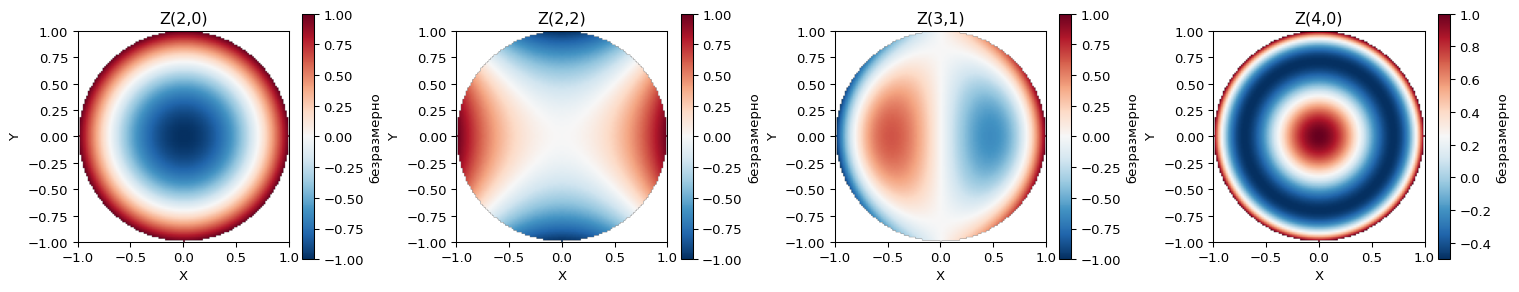

In [2]:
x,y=cl.grid(129)
disk=x*x+y*y<=1
selected=[(2,0),(2,2),(3,1),(4,0)]
cl.show_maps([cl.zernike(n,m,x,y) for n,m in selected],
             [f'Z({n},{m})' for n,m in selected],disk,cmap='RdBu_r',units='безразмерно')

## 3. Откуда берётся RMS-нормировка

Скалярное произведение на полном диске:
$\langle f,g\rangle=\frac1\pi\int_0^{2\pi}\int_0^1 fg\,\rho\,d\rho\,d\theta$.
Угловые интегралы равны 2π для m=0 и π для sin²/cos² ненулевого m.
Радиальный интеграл $\int_0^1[R_n^m]^2\rho d\rho=1/[2(n+1)]$.
Поэтому множитель для единичного RMS: $\sqrt{n+1}$ при m=0,
$\sqrt{2(n+1)}$ при m≠0.

При переходе к новому $P'_j=k_jP_j$ коэффициент меняется обратно:
$c'_j=c_j/k_j$. Карта и остаток должны остаться прежними.
На кольце, обрезанном диске или неравномерных весах эта ортогональность не сохраняется.

(2, 0) RMS unit / RMS normalized: 0.5766902749843689 0.9988568565037941
(2, 2) RMS unit / RMS normalized: 0.40716343754020146 0.9973426638910626
(3, 1) RMS unit / RMS normalized: 0.3529535145663793 0.9983032943740467
(4, 0) RMS unit / RMS normalized: 0.44622067863064496 0.9977797703842098


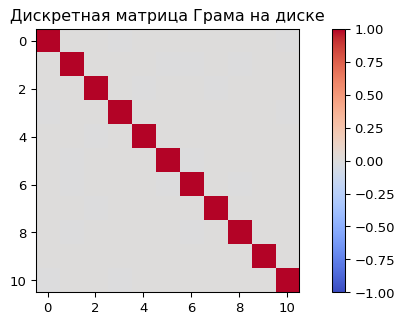

In [3]:
for n,m in selected:
    unit=cl.zernike(n,m,x,y)
    rms=cl.zernike(n,m,x,y,'rms')
    print((n,m),'RMS unit / RMS normalized:',np.sqrt(np.mean(unit[disk]**2)),np.sqrt(np.mean(rms[disk]**2)))
A=np.column_stack([cl.zernike(n,m,x,y,'rms')[disk] for n,m in cl.TERMS])
gram=A.T@A/disk.sum()
plt.imshow(gram,cmap='coolwarm',vmin=-1,vmax=1); plt.colorbar(); plt.title('Дискретная матрица Грама на диске')
plt.show()

## 4. Совместный МНК и QR

Для фактических валидных точек строим A. Решение МНК корректно и для неортогонального
базиса при полном ранге. В QR-разложении $A=QR$, $Q^TQ=I$:
$$q=Q^Tz,\qquad Rc=q.$$
Числа q — коэффициенты в ортонормированном **на этих отсчётах** базисе Q;
числа c — коэффициенты исходных полиномов. Печатать q под именами c нельзя.

Если сначала ортогонализовать полную иерархию, а потом отключать некоторые Q-термы,
коэффициенты оставшихся Q не меняются. Но отключение исходных P и повторный МНК —
другая операция. Это объясняет разницу режимов выбора термов.

Коэффициенты P: [ 0.1   0.05 -0.03  0.12  0.06 -0.04  0.02  0.01  0.   -0.    0.03]
Коэффициенты Q: [-10.41269   2.55974  -1.48963  -7.25024   2.45843   1.43859   0.50016
   0.13555  -0.05996   0.0653   -1.3229 ]
κ(A): 6.5862336933455365


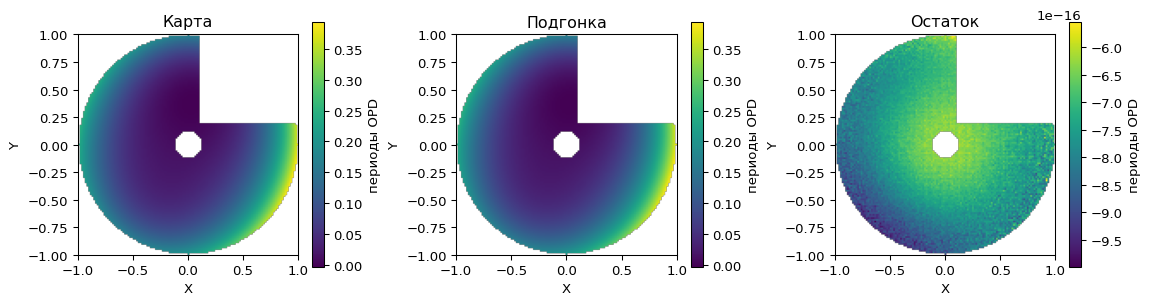

In [4]:
true_c=np.array([.1,.05,-.03,.12,.06,-.04,.02,.01,0,0,.03])
surface=sum(c*cl.zernike(n,m,x,y) for c,(n,m) in zip(true_c,cl.TERMS))
mask=disk & ~((x>.1)&(y>.2)) & (x*x+y*y>.12**2)
fit=cl.modal_fit(surface,x,y,mask)
A=fit['matrix']; z=surface[mask]
Q,R=np.linalg.qr(A,mode='reduced')
q=Q.T@z; c_qr=np.linalg.solve(R,q)
assert np.allclose(c_qr,true_c,atol=1e-10)
assert np.allclose(fit['coefficients'],true_c,atol=1e-10)
print('Коэффициенты P:',c_qr)
print('Коэффициенты Q:',q)
print('κ(A):',fit['condition'])
cl.show_maps([surface,fit['fitted'],fit['residual']],['Карта','Подгонка','Остаток'],mask,units='периоды OPD')

## 5. Неоднозначность и число обусловленности

Если точки лежат на одной строке, часть двумерных полиномов становится зависимой.
Если все точки на одной окружности, радиальные функции могут совпадать с константой.
Большое количество точек не восстанавливает недостающую геометрию.

Ранг выявляет численную неоднозначность; отношение сингулярных чисел показывает
чувствительность к возмущениям. Порог ранга — численное решение, а не допуск
на точность измерительного прибора. Для взвешенного МНК решают
$\|\sqrt{W}(Ac-z)\|^2$; квадратные корни весов умножают строки A и z.

In [5]:
line_mask=np.zeros_like(disk); line_mask[len(x)//2,:]=True
try:
    cl.modal_fit(surface,x,y,line_mask)
except ValueError as error:
    print('Полная 2D-подгонка по линии:',error)
piston=cl.modal_fit(surface,x,y,line_mask,terms=[(0,0)])
print('Один пистон на той же линии:',piston['coefficients'])

Полная 2D-подгонка по линии: Термы не независимы на данной апертуре
Один пистон на той же линии: [0.08776]


## 6. Что делает последовательная схема Серегина

В проекте есть legacy-схема: сначала наклон/пистон, затем дефокус,
астигматизм, кома/трилистник и радиальные члены более высоких порядков.
Каждый этап подгоняет **остаток предыдущих этапов**, а не исходную карту.
Некоторые низшие функции участвуют повторно. Интерсепты этапов нужно учитывать
при вычислении остатка, даже если их не показывают как отдельные характеристики.

Это последовательность проекций на разные подпространства. На неортогональных
подпространствах перестановка этапов меняет результат. Она не эквивалентна общему
совместному МНК и не обязана давать те же коэффициенты на произвольной апертуре.
Её ценность — воспроизведение определённого алгоритма сравнения, при известных
соглашениях. Углы также зависят от направления Y, начала отсчёта и кратности угла:
астигматизм имеет период 180°, трилистник 120°.

RMS остатка совместного МНК: 4.5461845267076314e-17
RMS по этапам Серегина: [0.07672 0.03324 0.01554 0.01339 0.      0.      0.     ]


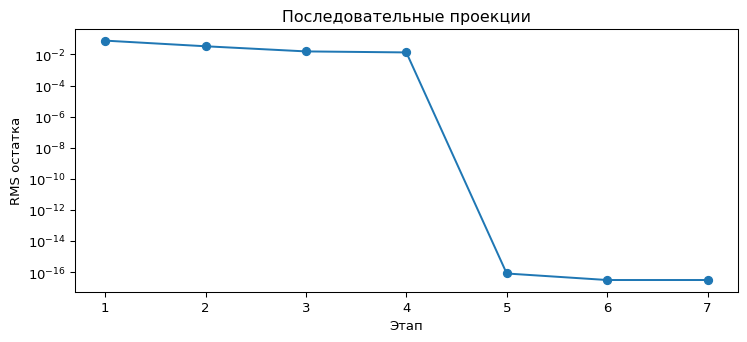

In [6]:
legacy=cl.sequential_seregin(surface,x,y,disk)
joint=cl.modal_fit(surface,x,y,disk)
print('RMS остатка совместного МНК:',np.sqrt(np.nanmean(joint['residual']**2)))
print('RMS по этапам Серегина:',legacy['history'])
plt.semilogy(np.arange(1,8),np.maximum(legacy['history'],1e-18),'o-')
plt.xlabel('Этап'); plt.ylabel('RMS остатка'); plt.title('Последовательные проекции')
plt.show()

## Задания

1. Подгоните одну карту в unit- и RMS-нормировках; проверьте совпадение карт, а не чисел c.
2. Уберите столбец комы и посмотрите, как меняется наклон на обрезанной апертуре.
3. Сравните AᵀA на полном диске и на маске с вырезом.
4. Почему нулевой остаток не подтверждает знак и масштаб исходной карты?

<details><summary>Разбор</summary>

Нормировки связаны обратным масштабом коэффициентов. На произвольной области
столбцы коррелируют, поэтому часть исключённой комы может описаться наклоном.
Матрица Грама показывает эти корреляции. Перевёрнутая или удвоенная карта тоже
лежит в том же полиномиальном пространстве и может иметь нулевой остаток.
</details>

**В проекте:** `ModalAnalysisStage.cpp`, `ZernikeNormalization.h`, `ModalAnalysisReportData.cpp`.
Режимы подгонки и базисы — разные переключатели. Эмпирические множители legacy-отчёта
нельзя объявлять математически выведенной нормировкой без отдельной проверки.
**Чтение:** [NumPy lstsq](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html).
Далее: [метрология и калибровка](11_calibration_and_quality.ipynb).